# 모델 도구 루프와 정지 조건

이 절은 모델이 다음 행동을 고르고 코드가 그 도구를 부르는 반복을 직접 만듭니다.
반복을 멈추는 조건도 코드에 적고, 어느 조건에서 멈췄는지 기록에 남깁니다.

**이 노트북에서 할 일**

1. 이 절에서 만든 도구 흉내 셋과 모델에게 보낼 요청 글을 만듭니다.
2. 모델이 JSON 글로 다음 행동을 고르고, 코드가 그 도구를 부르는 루프를 실행합니다.
3. 모델이 끝을 고를 때와 사람 확인에서 루프가 멈추는 것을 봅니다.
4. 바퀴 한도와 사람 확인 도구 목록을 바꿔 멈춘 까닭과 모델 요청 수를 견주고, 바퀴 한도로 멈추는 줄을 확인합니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 바퀴마다 한 번 나갑니다.
모델이 이 절의 예상대로 고르면 12번이고, 바퀴 한도 때문에 15번을 넘지 않습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 이 절에서 만든 파이썬 함수라 바깥 서비스를 부르지 않습니다.
읽는 자료 파일도 새로 쓰는 파일도 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 30초 안에 끝났습니다.

**기준 버전** — 패키지는 `langchain` 1.4.0, `langchain-openai` 1.6.1, `python-dotenv` 1.2.3입니다.
실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~8절을 읽습니다.
요청 글을 만들고 루프를 두 문의로 실행하는 자리입니다.
9·10절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 초록 상자 문의와 지금까지의 기록 부른 도구와 결과에서 오른쪽 파란 상자 ask_next 요청 글을 만들어 모델에 보냄으로 이어지고 보라 상자 gpt-5.4-mini 다음 행동을 JSON 글로 고름을 지나 파란 상자 stop_reason 멈출 까닭이 있는가에 닿으며 거기서 점선 둘이 나와 까닭 없음이면 왼쪽 아래 파란 상자 run_tool 이 절의 도구 흉내로 까닭 있음이면 오른쪽 아래 노란 상자 멈춤 모델이 끝을 고름 사람 확인 같은 도구를 다시 고름으로 가고 run_tool에서 실선이 결과를 기록에 더함을 지나 맨 위 초록 상자로 되돌아가며 초록 상자 바로 아래로 점선 하나가 바퀴를 다 쓰면 노란 상자 멈춤 바퀴 한도로 가는 그림](attachment:03-1-모델-도구-루프.png)

위에서 아래로 읽습니다.
보라 모델이 다음 행동을 고르고, 파란 코드가 멈출지 정한 뒤 도구를 부릅니다.
도구 결과는 실선을 따라 맨 위 초록 기록으로 되돌아가고, 그 자리에서 다음 바퀴가 시작됩니다.
노란 상자 둘이 루프가 멈추는 자리입니다.
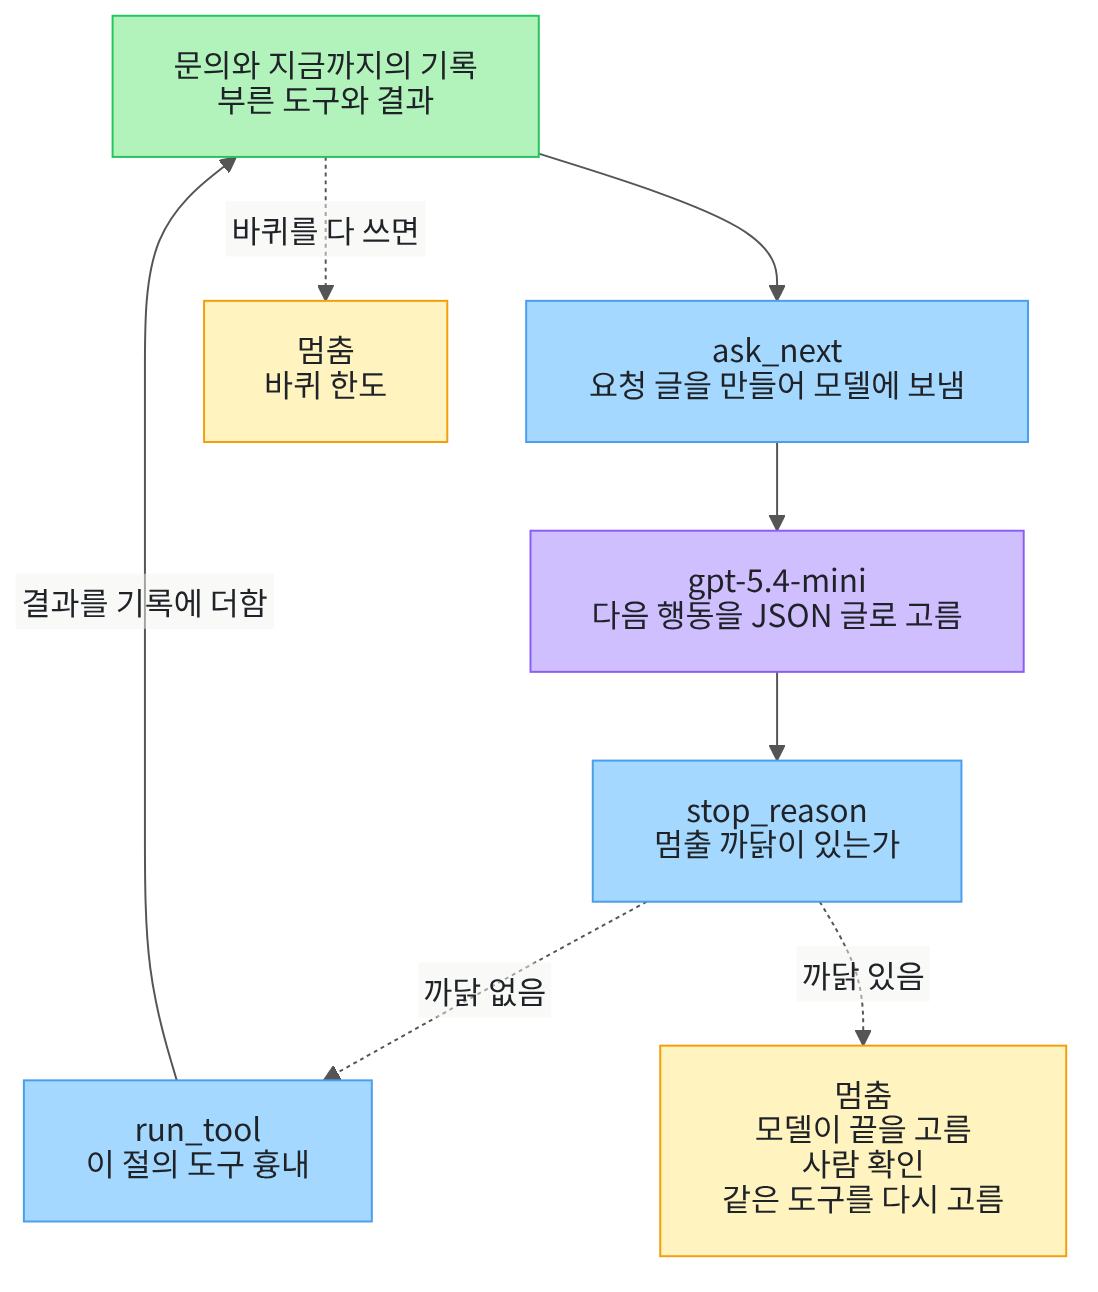

## 1. 준비

이 절은 실제 모델을 부릅니다.
첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
앞에서 배운 함수는 `agent_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

01절 함수 `classify`·`count_steps`에 더해 02절 함수 `tool_names`를 이 절에서 처음 가져옵니다.
함수 `tool_names`는 02절 노트북과 같은 본문으로 도구 파일에 옮겼습니다.

In [2]:
# 모델 글을 읽을 이름과 모델 준비 함수, 01·02절에서 배운 함수 셋을 불러옵니다
import json

from agent_tools import classify, count_steps, tool_names
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "init_chat_model")
print("가져온 함수:", "classify", "count_steps", "tool_names")

불러온 이름: json init_chat_model
가져온 함수: classify count_steps tool_names


**결과 읽기** — 출력 줄 `불러온 이름: json init_chat_model`과 `가져온 함수: classify count_steps tool_names`가 보입니다.
이름 `json`은 Ch 15 02절처럼 모델이 보낸 JSON 글을 읽을 때 씁니다.
이름 `init_chat_model`은 Ch 6부터 쓴 모델 준비 함수입니다.

## 2. 키와 모델 준비

이 절은 다음 행동을 고르는 모델로 `gpt-5.4-mini`를 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 모델이 고르는 행동이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 도구 흉내 셋

01절에서 도구는 모델 밖에서 정해진 일 하나를 하는 함수나 서비스라고 했습니다.
이 절의 도구는 이 절에서 만든 도구 흉내입니다.
바깥 서비스를 부르지 않고, 정해 둔 결과 글을 내놓는 파이썬 함수입니다.
그래서 같은 도구를 부르면 결과 글이 매번 같습니다.

다음 셀은 도구 이름 셋을 적습니다.
02절 환불 절차 기록에 나온 도구 이름과 같습니다.
그 가운데 환불 요청 등록은 02절에서 말한 부작용이 있는 도구로 봅니다.
그래서 부르기 전에 사람이 확인해야 하는 도구 목록에 따로 적습니다.

In [5]:
# 이 절에서 쓸 도구 이름 셋과, 부르기 전에 사람이 확인해야 하는 도구를 적습니다
tool_list = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
confirm_tools = ["환불 요청 등록"]
print("도구 이름:", tool_list)
print("사람 확인이 필요한 도구:", confirm_tools)

도구 이름: ['주문 조회', '환불 규정 확인', '환불 요청 등록']
사람 확인이 필요한 도구: ['환불 요청 등록']


**결과 읽기** — 출력 줄 `도구 이름: ['주문 조회', '환불 규정 확인', '환불 요청 등록']`이 보입니다.
출력 줄 `사람 확인이 필요한 도구: ['환불 요청 등록']`은 이름 하나만 담은 목록입니다.
6절에서 이 목록으로 멈출지를 정합니다.

다음 셀은 도구 이름을 받아 결과 글을 내놓는 도구 흉내입니다.
01절 함수 `pick_next_step`처럼 `if` 여러 개로 이름을 가릅니다.
목록에 없는 이름을 받으면 `목록에 없는 도구`라는 글을 내놓습니다.

In [6]:
# 도구 흉내: 도구 이름을 받아 이 절에서 정해 둔 결과 글을 내놓습니다
def run_tool(tool_name):
    if tool_name == "주문 조회":
        return "주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일"
    if tool_name == "환불 규정 확인":
        return "받은 지 7일 안의 상품은 환불할 수 있음"
    if tool_name == "환불 요청 등록":
        return "환불 요청을 등록함"
    return "목록에 없는 도구"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_tool`은 주문 A-1024 하나에 대한 결과만 알고 있습니다.
실제 주문을 조회하거나 환불을 등록하지 않습니다.

다음 셀은 도구 흉내를 이름마다 한 번씩 부릅니다.
목록에 없는 이름 `배송 추적`도 한 번 넣어 봅니다.

In [7]:
# 도구 흉내를 이름마다 한 번씩 불러 결과 글을 봅니다(모델 요청 없음)
print("도구 이름 | 결과")
for tool_name in tool_list:
    print(tool_name, "|", run_tool(tool_name))
print("배송 추적 |", run_tool("배송 추적"))

도구 이름 | 결과
주문 조회 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
환불 규정 확인 | 받은 지 7일 안의 상품은 환불할 수 있음
환불 요청 등록 | 환불 요청을 등록함
배송 추적 | 목록에 없는 도구


**결과 읽기** — 라벨 줄 `도구 이름 | 결과` 아래 네 줄이 도구 흉내의 결과 글입니다.
출력 줄 `주문 조회 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일`이 첫 도구의 결과입니다.
출력 줄 `환불 규정 확인 | 받은 지 7일 안의 상품은 환불할 수 있음`이 규정 글입니다.
마지막 줄 `배송 추적 | 목록에 없는 도구`처럼 없는 이름에도 멈추지 않고 글을 내놓습니다.

## 4. 모델에게 보낼 요청 글

모델에게 다음 행동을 고르게 하려면 고를 수 있는 도구 이름을 글로 알려야 합니다.
답 모양도 정해 두어야 코드가 그 답을 읽을 수 있습니다.
다음 셀은 요청마다 같이 보낼 머리글을 만듭니다.
Ch 16 01절에서 쓴 `join`으로 도구 이름 셋을 쉼표로 이어 붙입니다.

머리글 마지막 줄이 답 모양입니다.
칸 「다음」에는 도구 이름이나 `끝`을, 칸 「까닭」에는 한 문장을 적게 합니다.
Ch 15 02절 판정 머리글처럼 JSON만 출력하라고 적었습니다.

In [8]:
# 바퀴마다 모델에게 같이 보낼 머리글입니다: 할 일, 도구 이름, 답 모양
request_head = "손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.\n"
request_head = request_head + "쓸 수 있는 도구: " + ", ".join(tool_list) + "\n"
request_head = request_head + "더 부를 도구가 없으면 끝을 고르세요.\n"
request_head = request_head + 'JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}'
print("머리글:")
print(request_head)

머리글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}


**결과 읽기** — 라벨 줄 `머리글:` 아래 네 줄이 모델이 요청마다 받을 첫머리 글입니다.
둘째 줄 `쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록`에 도구 이름이 이어 붙었습니다.
셋째 줄은 더 부를 도구가 없으면 끝을 고르라고 말합니다.
넷째 줄이 답 모양이고, 칸 「다음」과 칸 「까닭」 두 칸입니다.

머리글은 매번 같습니다. 바뀌는 것은 문의와 지금까지 부른 도구의 결과입니다.
이 절의 기록 한 줄은 01절 칸 셋 「단계」·「한 쪽」·「고른 쪽」에 칸 「결과」를 더합니다.

다음 셀은 머리글 뒤에 문의와 도구 결과를 이어 붙이는 함수입니다.
기록에서 칸 「한 쪽」이 `도구`인 줄만 골라 도구 이름과 결과 글을 한 줄씩 적습니다.
부른 도구가 아직 없으면 `없음`을 적고, 도구 줄 수는 01절 함수 `count_steps`로 셉니다.

In [9]:
# 머리글 뒤에 문의와 지금까지 부른 도구의 결과를 이어 붙여 요청 글 하나를 만듭니다
def build_request(head, question, steps):
    text = head + "\n\n문의: " + question + "\n지금까지 부른 도구와 결과:"
    if count_steps(steps, "한 쪽", "도구") == 0:
        text = text + " 없음"
    for step in steps:
        if step["한 쪽"] == "도구":
            text = text + "\n- " + step["단계"] + ": " + step["결과"]
    return text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_request`는 머리글과 문의, 기록을 받아 요청 글 하나를 내놓습니다.
기록에서 도구가 한 줄만 요청 글에 들어갑니다.

다음 셀은 첫 문의로 요청 글을 만들어 봅니다.
문의는 주문 A-1024가 도착했는지 묻는 글이고, 이 절에서 정한 문의입니다.
아직 부른 도구가 없으니 기록은 빈 목록 `[]`입니다.

In [10]:
# 도착 문의로 첫 바퀴의 요청 글을 만들어 그대로 봅니다(아직 모델을 부르지 않습니다)
delivery_question = "주문 A-1024가 도착했는지 알려 주세요."
first_request = build_request(request_head, delivery_question, [])
print("요청 글:")
print(first_request)

요청 글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}

문의: 주문 A-1024가 도착했는지 알려 주세요.
지금까지 부른 도구와 결과: 없음


**결과 읽기** — 라벨 줄 `요청 글:` 아래가 모델이 받을 글 전체입니다.
머리글 네 줄 뒤에 출력 줄 `문의: 주문 A-1024가 도착했는지 알려 주세요.`가 이어집니다.
마지막 줄 `지금까지 부른 도구와 결과: 없음`으로 첫 요청임을 알립니다.

## 5. 다음 행동 한 번 고르게 하기

이제 이 요청 글을 모델에 보냅니다.
모델이 보낸 글을 먼저 그대로 보고, 그다음에 읽습니다.

In [11]:
# 그 요청 글을 모델에 보내고 받은 글을 그대로 출력합니다(모델 요청 1번)
first_reply = model.invoke(first_request)
print("모델이 보낸 글:")
print(first_reply.text)

모델이 보낸 글:
{"다음":"주문 조회","까닭":"주문 A-1024의 배송/도착 상태를 확인하려면 주문 조회 도구가 필요합니다."}


**결과 읽기** — 라벨 줄 `모델이 보낸 글:` 아래 한 줄이 모델이 보낸 JSON 글입니다.
칸 `"다음"`의 값이 `"주문 조회"`입니다.
머리글이 적은 답 모양 그대로 칸 「다음」과 칸 「까닭」이 들어 있습니다.

이번 실행에서는 칸 「까닭」에 배송·도착 상태를 확인하려면 주문 조회 도구가 필요하다는 문장이 적혔습니다.
까닭은 모델이 쓴 문장이라 실행마다 달라질 수 있습니다.
노트북을 실행하기 전에 노트북 밖에서 같은 요청을 다섯 번 보냈고, 칸 「다음」은 다섯 번 모두 주문 조회였습니다.

다음 셀은 받은 JSON 글을 Ch 15 02절처럼 `json.loads`로 딕셔너리로 읽습니다.

In [12]:
# 받은 JSON 글을 딕셔너리로 읽고 다음 행동과 까닭을 따로 꺼냅니다
first_choice = json.loads(first_reply.text)
print("다음:", first_choice["다음"])
print("까닭:", first_choice["까닭"])

다음: 주문 조회
까닭: 주문 A-1024의 배송/도착 상태를 확인하려면 주문 조회 도구가 필요합니다.


**결과 읽기** — 출력 줄 `다음: 주문 조회`로 모델이 고른 다음 행동을 꺼냈습니다.
출력 줄 `까닭:` 뒤는 모델이 쓴 한 문장이고, 실행마다 달라질 수 있습니다.
함수 `json.loads`가 JSON 글을 딕셔너리로 바꿔 칸 이름으로 값을 꺼낼 수 있습니다.

다음 셀은 요청 글 만들기, 보내기, 읽기를 함수 하나로 묶습니다.
모델도 인자로 받아 어느 모델에게 물었는지 드러나게 합니다.
이 함수는 부를 때마다 모델 요청을 한 번 보냅니다.

In [13]:
# 요청 글을 만들어 모델에 보내고, 받은 JSON 글에서 다음 행동 이름만 꺼냅니다(모델 요청 1번)
def ask_next(chat_model, head, question, steps):
    request_text = build_request(head, question, steps)
    reply = chat_model.invoke(request_text)
    choice = json.loads(reply.text)
    return choice["다음"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_next`는 모델이 고른 이름 하나만 내놓고 까닭 문장은 쓰지 않습니다.
받은 글이 JSON 모양이 아니면 `json.loads`에서 멈춥니다.
이번 실행에서는 그런 글을 받지 않았습니다.

## 6. 정지 조건

5절에서는 모델에게 다음 행동을 한 번 물었습니다.
7절에서는 묻고, 고른 도구를 부르고, 그 결과를 들고 다시 묻기를 되풀이합니다.
이 되풀이를 루프(loop)라고 부르고, 한 번 도는 차례를 바퀴라고 부릅니다.

모델이 끝을 고르지 않으면 루프는 계속 돕니다.
그래서 모델이 고른 이름을 코드가 먼저 보고 멈출지 정합니다.
정지 조건(stopping condition)은 반복을 멈추는 조건입니다.
눈밭을 걷다가 울타리 앞에서 발자국이 끝나는 것과 같습니다.

다음 셀은 모델이 고른 이름을 보고 멈출 까닭을 찾는 함수입니다.
모델이 `끝`을 고르면 `모델이 끝을 고름`, 사람 확인이 필요한 도구이면 `사람 확인`을 내놓습니다.
이미 부른 도구를 다시 고르면 `같은 도구를 다시 고름`을 내놓습니다.
이 절 도구는 인자가 없어 같은 도구를 다시 부르면 같은 결과만 받기 때문입니다.
멈출 까닭이 없으면 빈 글 `""`을 내놓습니다.

In [14]:
# 모델이 고른 이름을 보고 멈출 까닭을 찾습니다(멈추지 않으면 빈 글)
def stop_reason(name, steps, confirm_tools):
    if name == "끝":
        return "모델이 끝을 고름"
    if name in confirm_tools:
        return "사람 확인"
    if count_steps(steps, "단계", name) > 0:
        return "같은 도구를 다시 고름"
    return ""

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `stop_reason`은 끝, 사람 확인, 다시 고름 차례로 봅니다.
이름 뒤에 `in`과 목록을 두면 그 이름이 목록에 있는지 봅니다.
01절 함수 `count_steps`로 칸 「단계」에 그 이름이 있는 줄을 세어, 0보다 크면 이미 부른 도구입니다.

다음 셀은 손으로 적은 기록 한 줄로 이 함수를 확인합니다.
기록에는 주문 조회를 이미 부른 줄 하나만 있습니다.
조건이 참이 아니면 셀을 멈추는 `assert` 줄로 네 경우를 확인합니다.

In [15]:
# 손으로 적은 기록 한 줄로 멈추는 경우 셋과 멈추지 않는 경우 하나를 확인합니다
checked_steps = [{"단계": "주문 조회", "한 쪽": "도구", "고른 쪽": "모델", "결과": "주문 A-1024"}]
assert stop_reason("끝", checked_steps, confirm_tools) == "모델이 끝을 고름"
assert stop_reason("환불 요청 등록", checked_steps, confirm_tools) == "사람 확인"
assert stop_reason("주문 조회", checked_steps, confirm_tools) == "같은 도구를 다시 고름"
assert stop_reason("환불 규정 확인", checked_steps, confirm_tools) == ""
print("손 확인 통과:", stop_reason("주문 조회", checked_steps, confirm_tools))

손 확인 통과: 같은 도구를 다시 고름


**결과 읽기** — 출력 줄 `손 확인 통과: 같은 도구를 다시 고름`으로 네 `assert` 줄이 모두 지나갔습니다.
주문 조회를 이미 부른 기록에서 주문 조회를 다시 고르면 멈춥니다.
환불 규정 확인처럼 처음 고른 도구는 빈 글이 나와 멈추지 않습니다.

다음 셀은 멈춘 까닭을 기록 한 줄로 만드는 함수입니다.
칸 「단계」에 `멈춤`, 칸 「결과」에 멈춘 까닭을 적습니다.
멈춤 줄의 칸 「고른 쪽」은 누가 멈추기로 정했는지입니다.
모델이 끝을 골랐으면 `모델`, 코드가 조건으로 멈췄으면 `코드`입니다.

In [16]:
# 멈춘 까닭을 기록 한 줄로 만듭니다: 끝은 모델이 고른 멈춤, 나머지는 코드가 정한 멈춤
def stop_line(reason):
    chooser = "코드"
    if reason == "모델이 끝을 고름":
        chooser = "모델"
    return {"단계": "멈춤", "한 쪽": "코드", "고른 쪽": chooser, "결과": reason}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `stop_line`은 기록 한 줄 딕셔너리를 내놓습니다.
멈춘 까닭까지 기록에 남기면 기록만 보고도 왜 멈췄는지 알 수 있습니다.

다음 셀은 한 바퀴의 기록 줄을 만드는 함수입니다.
첫 줄은 02절 기록처럼 「다음 단계 고르기」 줄이고, 칸 「한 쪽」은 `모델`, 칸 「고른 쪽」은 `코드`입니다.
멈출 까닭이 있으면 둘째 줄이 멈춤 줄이고, 없으면 도구 흉내를 부른 줄입니다.

도구를 부른 줄은 칸 「고른 쪽」이 `모델`입니다. 그 도구를 모델이 골랐기 때문입니다.
기호 `!=`는 두 값이 다를 때 참이 되는 비교이고, Ch 16 07절에서 썼습니다.

In [17]:
# 한 바퀴의 기록 줄을 만듭니다: 고른 줄 뒤에 멈춤 줄 또는 도구를 부른 줄
def turn_lines(name, reason):
    choose = {"단계": "다음 단계 고르기", "한 쪽": "모델", "고른 쪽": "코드", "결과": name}
    if reason != "":
        return [choose, stop_line(reason)]
    result = run_tool(name)
    tool_step = {"단계": name, "한 쪽": "도구", "고른 쪽": "모델", "결과": result}
    return [choose, tool_step]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `turn_lines`는 기록 줄 두 개를 담은 목록을 내놓습니다.
멈출 까닭이 없을 때만 함수 `run_tool`을 부릅니다.
그래서 사람 확인에서 멈추면 그 도구는 불리지 않습니다.

다음 셀은 기록을 줄마다 출력하는 함수입니다.
01절 함수 `print_steps`와 같은 모양에 칸 「결과」를 더했습니다.

In [18]:
# 기록을 줄마다 번호·단계·한 쪽·고른 쪽·결과 차례로 출력합니다
def print_results(steps):
    print("번호 | 단계 | 한 쪽 | 고른 쪽 | 결과")
    for i in range(len(steps)):
        step = steps[i]
        print(i, "|", step["단계"], "|", step["한 쪽"], "|", step["고른 쪽"], "|", step["결과"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_results`는 라벨 줄을 먼저 출력하고, 기록 한 줄마다 한 줄씩 출력합니다.

다음 셀은 모델을 부르지 않고 두 바퀴의 기록 줄을 만들어 봅니다.
한 바퀴는 환불 규정 확인을, 다른 바퀴는 환불 요청 등록을 골랐다고 정했습니다.
둘째 바퀴에는 사람 확인에서 멈춘다는 까닭을 넣었습니다.
두 목록을 `+`로 이어 한 기록으로 출력합니다.

In [19]:
# 모델 없이 두 바퀴의 기록 줄을 만들어 봅니다: 도구를 부른 바퀴와 사람 확인에서 멈춘 바퀴
tool_turn = turn_lines("환불 규정 확인", "")
stop_turn = turn_lines("환불 요청 등록", "사람 확인")
print_results(tool_turn + stop_turn)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
1 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록
3 | 멈춤 | 코드 | 코드 | 사람 확인


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래 네 줄이 두 바퀴의 기록입니다.
출력 줄 `1 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음`이 도구를 부른 줄입니다.
마지막 줄 `3 | 멈춤 | 코드 | 코드 | 사람 확인`이 멈춤 줄입니다.
멈춘 바퀴에는 환불 요청 등록을 부른 줄이 없습니다.

## 7. 루프 · 도착 문의

이제 바퀴를 되풀이하는 루프 함수를 만듭니다.
바퀴마다 모델에게 다음 행동을 묻고, 멈출 까닭을 보고, 기록 줄을 더합니다.
멈출 까닭이 있으면 그 자리에서 기록을 내놓습니다.

바퀴 한도는 루프가 돌 수 있는 바퀴 수의 상한입니다.
걷는 사람이 멈추지 않아도 눈밭 둘레의 울타리 앞에서는 발자국이 끝나는 것과 같습니다.
코드에서는 `for`와 `range(turn_limit)`로 바퀴 수를 정합니다.
바퀴를 다 쓸 때까지 멈추지 않으면 마지막에 `바퀴 한도` 멈춤 줄을 더합니다.

In [20]:
# 루프: 바퀴마다 모델에게 다음 행동을 묻고, 멈출 까닭이 없으면 그 도구를 부릅니다
def run_loop(chat_model, head, question, confirm_tools, turn_limit):
    steps = []
    for turn in range(turn_limit):
        name = ask_next(chat_model, head, question, steps)
        reason = stop_reason(name, steps, confirm_tools)
        steps = steps + turn_lines(name, reason)
        if reason != "":
            return steps
    return steps + [stop_line("바퀴 한도")]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_loop`는 모델, 머리글, 문의, 사람 확인 도구 목록, 바퀴 한도를 인자로 받습니다.
반복문 안의 `return`은 바퀴가 남아 있어도 함수를 바로 끝내고, Ch 16 05절에서 쓴 모양입니다.
어느 조건으로 멈췄든 마지막 줄은 늘 멈춤 줄입니다.

다음 셀은 도착 문의로 루프를 실행합니다.
바퀴 한도는 4로 두었고, 흐름을 보여 주려고 이 절에서 정한 값입니다.
바퀴마다 모델 요청이 한 번 나가므로 이 셀은 모델 요청을 네 번까지 보냅니다.

In [21]:
# 도착 문의로 루프를 실행합니다: 바퀴 한도 4(바퀴마다 모델 요청 1번)
turn_limit = 4
delivery_steps = run_loop(model, request_head, delivery_question, confirm_tools, turn_limit)
print_results(delivery_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 끝
3 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름


**결과 읽기** — 라벨 줄 아래 네 줄이 도착 문의의 기록입니다.
출력 줄 `0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회`에서 모델이 주문 조회를 골랐습니다.
출력 줄 `2 | 다음 단계 고르기 | 모델 | 코드 | 끝`에서 둘째 바퀴에 끝을 골랐습니다.
마지막 줄 `3 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름`에서 멈추기로 정한 쪽은 모델입니다.

주문 조회 결과에 배송 완료가 있었고, 모델은 그다음 바퀴에 끝을 골랐습니다.
바퀴 한도 4 가운데 두 바퀴만 썼고, 모델 요청은 두 번 나갔습니다.

## 8. 환불 문의 · 사람 확인에서 멈춤

다음 문의는 주문 A-1024를 환불해 달라는 글이고, 이 절에서 정한 문의입니다.
머리글과 도구, 바퀴 한도 4는 그대로 두고 문의만 바꿉니다.
환불 요청 등록은 사람 확인이 필요한 도구라, 모델이 고르면 부르기 전에 멈춰야 합니다.

In [22]:
# 환불 문의로 같은 루프를 실행합니다(바퀴 한도 4 그대로)
refund_question = "주문 A-1024를 환불해 주세요."
refund_steps = run_loop(model, request_head, refund_question, confirm_tools, turn_limit)
print_results(refund_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록
5 | 멈춤 | 코드 | 코드 | 사람 확인


**결과 읽기** — 라벨 줄 아래 여섯 줄이 환불 문의의 기록입니다.
출력 줄 `4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록`이 셋째 바퀴의 선택입니다.
마지막 줄 `5 | 멈춤 | 코드 | 코드 | 사람 확인`에서 코드가 부르기 전에 멈췄습니다.
모델은 주문 조회, 환불 규정 확인, 환불 요청 등록 차례로 골랐습니다.

기록에 환불 요청 등록을 부른 줄은 없습니다.
02절에서 부작용 앞에 사람이 확인하는 자리를 승인 지점이라고 불렀습니다.
사람 확인은 루프가 그 자리에 닿으면 반복을 멈추고 사람에게 넘기는 정지 조건입니다.
이 절은 멈추기까지만 하고, 사람이 확인한 뒤 이어 가는 장면은 다루지 않습니다.

다음 셀은 기록 여러 개를 한 줄씩 요약하는 함수입니다.
01절 함수 `count_steps`·`classify`와 02절 함수 `tool_names`를 씁니다.
칸 「한 쪽」이 모델인 줄 하나를 모델 요청 한 번으로 세는 것은 02절에서 정한 약속입니다.
이 절에서는 그 줄마다 실제로 모델 요청이 한 번 나갔습니다.

In [23]:
# 기록마다 모델 요청 수·도구 차례·멈춘 까닭·구조를 한 줄로 출력합니다
def print_summary(runs):
    print("기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조")
    for run in runs:
        steps = run["기록"]
        request_count = count_steps(steps, "한 쪽", "모델")
        tools = tool_names(steps)
        reason = steps[-1]["결과"]
        print(run["이름"], "|", request_count, "|", tools, "|", reason, "|", classify(steps))

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_summary`는 칸 「이름」과 칸 「기록」을 가진 딕셔너리의 목록을 받습니다.
01절 사례와 같은 모양입니다.
멈춘 까닭은 기록 마지막 줄 `steps[-1]`의 칸 「결과」에서 꺼냅니다.

다음 셀은 두 문의의 기록을 한 표로 견줍니다.

In [24]:
# 두 문의의 기록을 한 표로 견줍니다
first_runs = [
    {"이름": "도착 문의", "기록": delivery_steps},
    {"이름": "환불 문의", "기록": refund_steps},
]
print_summary(first_runs)

기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조
도착 문의 | 2 | ['주문 조회'] | 모델이 끝을 고름 | 에이전트 후보
환불 문의 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보


**결과 읽기** — 라벨 줄 `기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조` 아래 두 줄을 견줍니다.
출력 줄 `도착 문의 | 2 | ['주문 조회'] | 모델이 끝을 고름 | 에이전트 후보`가 첫 기록입니다.
출력 줄 `환불 문의 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보`가 둘째 기록입니다.
두 기록 모두 도구를 모델이 골라 01절 규칙으로 에이전트 후보입니다.

같은 루프 함수인데 문의에 따라 바퀴 수와 멈춘 까닭이 달랐습니다.
도착 문의는 모델이 멈췄고, 환불 문의는 코드가 멈췄습니다.
어느 도구를 몇 번 부를지는 코드에 적혀 있지 않고, 모델이 고른 결과입니다.

## 9. 값 바꿔 보기 · 바퀴 한도

바꿀 값은 바퀴 한도 하나입니다. 4에서 2로 낮추고 환불 문의로 다시 실행합니다.
문의와 머리글, 사람 확인 도구 목록은 그대로 둡니다.

실행 전에 예상해 봅니다.
첫 두 바퀴는 8절과 요청 글이 같아 주문 조회와 환불 규정 확인을 고를 것입니다.
셋째 바퀴가 오기 전에 바퀴 한도로 멈추고, 모델 요청은 두 번일 것입니다.

In [25]:
# 바꿀 값 1: 바퀴 한도를 2로 낮추고 환불 문의로 다시 실행합니다
short_limit = 2
short_steps = run_loop(model, request_head, refund_question, confirm_tools, short_limit)
print_results(short_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 멈춤 | 코드 | 코드 | 바퀴 한도


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래 다섯 줄이 바퀴 한도 2의 기록입니다.
모델은 첫 두 바퀴에 8절처럼 주문 조회와 환불 규정 확인을 골랐습니다.
마지막 줄 `4 | 멈춤 | 코드 | 코드 | 바퀴 한도`에서 바퀴 둘을 다 쓴 뒤 코드가 멈췄습니다.
셋째 바퀴가 오지 않아 환불 요청 등록을 고를 차례도 없었고, 두 예상 모두 맞았습니다.

8·9·10절 첫 바퀴는 같은 요청 글이지만, 실행한 때에 따라 모델이 다른 행동을 고를 수 있습니다.
첫 바퀴에 환불 요청 등록을 골랐다면, 사람 확인으로 멈추고 모델 요청은 1번이 됩니다.

다음 셀은 바퀴 한도 4와 2의 기록을 견줍니다.

In [26]:
# 바퀴 한도 4와 2의 환불 문의 기록을 견줍니다
limit_runs = [
    {"이름": "바퀴 한도 4", "기록": refund_steps},
    {"이름": "바퀴 한도 2", "기록": short_steps},
]
print_summary(limit_runs)

기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조
바퀴 한도 4 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보
바퀴 한도 2 | 2 | ['주문 조회', '환불 규정 확인'] | 바퀴 한도 | 에이전트 후보


**결과 읽기** — 라벨 줄 `기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조` 아래 두 줄을 견줍니다.
출력 줄 `바퀴 한도 4 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보`가 8절 기록입니다.
출력 줄 `바퀴 한도 2 | 2 | ['주문 조회', '환불 규정 확인'] | 바퀴 한도 | 에이전트 후보`가 이번 기록입니다.
부른 도구는 같고, 한도를 낮추자 모델 요청이 하나 줄고 멈춘 까닭이 바뀌었습니다.

첫 바퀴에 환불 요청 등록을 골라 사람 확인으로 멈췄다면, 이 줄의 구조는 워크플로우가 됩니다.
이 절 기록은 모델이 고른 도구를 부른 줄과 모델이 끝을 고른 멈춤 줄에만 칸 「고른 쪽」을 `모델`로 적습니다.
코드가 부르기 전에 멈추면 모델이 고른 이름은 칸 「결과」에만 남아, 01절 규칙은 이 선택을 세지 못합니다.
01절은 기록으로 그 실행에서 누가 다음 단계를 골랐는지 안다고 했습니다.
이 기록 모양에서는 누가 멈췄는지에 따라 그 판정이 갈립니다.

**손 확인 · 바퀴 한도로 멈추는 줄**

9절 실행이 어디서 멈추는지는 모델이 첫 두 바퀴에 무엇을 고르느냐에 달려 있습니다.
그래서 바퀴 한도로 멈추는 줄을 모델 요청 없이 한 번 더 확인합니다.
다음 셀의 함수는 7절 함수 `run_loop`와 같은 차례로 돕니다.
다른 점은 하나입니다. 함수 `ask_next`로 모델에게 묻는 대신, 목록에 정해 둔 이름을 바퀴 차례대로 꺼냅니다.

In [27]:
# 모델 대신 목록에 정해 둔 이름을 바퀴 차례대로 꺼내 도는 루프입니다(모델 요청 0번)
def run_planned_loop(planned_names, confirm_tools, turn_limit):
    steps = []
    for turn in range(turn_limit):
        name = planned_names[turn]
        reason = stop_reason(name, steps, confirm_tools)
        steps = steps + turn_lines(name, reason)
        if reason != "":
            return steps
    return steps + [stop_line("바퀴 한도")]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_planned_loop`는 모델을 부르지 않아 모델 요청이 0번입니다.
바퀴 번호 `turn` 자리의 이름을 `planned_names[turn]`으로 꺼냅니다.
바퀴를 다 쓸 때까지 멈출 까닭이 없으면, 7절 루프처럼 `바퀴 한도` 멈춤 줄을 더합니다.

다음 셀은 이름 셋을 목록에 적고, 바퀴 한도 2로 이 함수를 부릅니다.
이 셀은 모델 대신 정해 둔 선택을 씁니다.
첫 두 이름은 8절에서 모델이 첫 두 바퀴에 고른 이름과 같게 적었습니다.

In [28]:
# 이 셀은 모델 대신 정해 둔 선택을 씁니다: 이름 셋으로 바퀴 한도 2의 루프를 돌립니다(모델 요청 0번)
planned_names = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
planned_steps = run_planned_loop(planned_names, confirm_tools, short_limit)
print_results(planned_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 멈춤 | 코드 | 코드 | 바퀴 한도


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래 다섯 줄이 정해 둔 선택으로 돈 기록입니다.
마지막 줄 `4 | 멈춤 | 코드 | 코드 | 바퀴 한도`가 바퀴 둘을 다 쓴 뒤 코드가 더한 멈춤 줄입니다.
이름 셋 가운데 두 이름만 쓰였고, 셋째 이름 환불 요청 등록은 꺼내지 않았습니다.
칸 「한 쪽」의 `모델`은 함수 `turn_lines`가 적는 값이고, 이 셀에서는 그 자리에 정해 둔 이름이 들어갔습니다.

이번 실행에서는 위 9절 모델 실행의 기록도 이 다섯 줄과 같았습니다.
이 셀은 모델 요청 없이, 바퀴 한도로 멈추는 줄을 실행할 때마다 같게 보여 줍니다.

바퀴 한도는 모델이 무엇을 고르든 모델 요청이 그 수를 넘지 않게 묶습니다.
다만 한도가 너무 낮으면 필요한 도구를 다 부르기 전에 멈춥니다.
이 절의 바퀴 한도 4와 2는 흐름을 보여 주려고 정한 값입니다.

## 10. 값 바꿔 보기 · 사람 확인 빼기

이번에는 바퀴 한도를 4로 두고, 사람 확인이 필요한 도구 목록을 빈 목록으로 바꿉니다.
사람 확인이라는 정지 조건 하나를 빼는 것입니다.
환불 요청 등록은 도구 흉내라 불러도 실제로 바뀌는 것은 없습니다.

실행 전에 예상해 봅니다.
셋째 바퀴에서 모델이 환불 요청 등록을 고르면 이번에는 멈추지 않고 부를 것입니다.
넷째 바퀴에서는 모델이 끝을 고를 것으로 예상합니다.

In [29]:
# 바꿀 값 2: 사람 확인이 필요한 도구 목록을 비우고 환불 문의로 다시 실행합니다
no_confirm = []
open_steps = run_loop(model, request_head, refund_question, no_confirm, turn_limit)
print_results(open_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록
5 | 환불 요청 등록 | 도구 | 모델 | 환불 요청을 등록함
6 | 다음 단계 고르기 | 모델 | 코드 | 끝
7 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름


**결과 읽기** — 라벨 줄 아래 여덟 줄이 사람 확인을 뺀 기록입니다.
출력 줄 `5 | 환불 요청 등록 | 도구 | 모델 | 환불 요청을 등록함`에서 등록 도구가 불렸습니다.
마지막 줄 `7 | 멈춤 | 코드 | 모델 | 모델이 끝을 고름`에서 넷째 바퀴에 모델이 끝을 골랐습니다.
두 예상 모두 맞았습니다.

다음 셀은 사람 확인이 있을 때와 없을 때를 견줍니다.
02절에서 코드가 고른 환불 기록의 도구 차례와도 견줍니다.

In [30]:
# 사람 확인이 있을 때와 없을 때를 견주고, 02절 코드가 고른 도구 차례와도 견줍니다
confirm_runs = [
    {"이름": "사람 확인 있음", "기록": refund_steps},
    {"이름": "사람 확인 없음", "기록": open_steps},
]
print_summary(confirm_runs)
code_order = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
print("02절 코드 차례와 같은가:", tool_names(open_steps) == code_order)

기록 | 모델 요청 | 도구 차례 | 멈춘 까닭 | 구조
사람 확인 있음 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보
사람 확인 없음 | 4 | ['주문 조회', '환불 규정 확인', '환불 요청 등록'] | 모델이 끝을 고름 | 에이전트 후보
02절 코드 차례와 같은가: True


**결과 읽기** — 라벨 줄 아래 두 줄을 견줍니다.
출력 줄 `사람 확인 있음 | 3 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보`가 8절 기록입니다.
출력 줄 `사람 확인 없음 | 4 | ['주문 조회', '환불 규정 확인', '환불 요청 등록'] | 모델이 끝을 고름 | 에이전트 후보`가 이번 기록입니다.
출력 줄 `02절 코드 차례와 같은가: True`로 모델이 고른 도구 차례가 02절 코드 차례와 같았습니다.

정지 조건 하나를 빼자 부작용이 있는 도구가 불렸고 모델 요청도 하나 늘었습니다.
이 절 도구는 흉내라 바뀐 것이 없지만, 실제 서비스였다면 환불 요청이 등록됐을 것입니다.
02절은 모델이 코드와 같은 차례를 골랐다고 정해 적었습니다.
이번 문의에서는 실제 모델도 같은 차례를 골랐습니다.
다른 문의에서도 같은지는 이 절에서 확인하지 않았습니다.

## 정리

1. 모델이 JSON 글로 다음 행동을 고르고 코드가 그 도구를 부르는 루프를 만들었습니다.
2. 도착 문의는 모델이 끝을 골라 멈췄고, 환불 문의는 코드가 사람 확인에서 멈췄습니다.
3. 바퀴 한도 2에서는 모델 요청이 두 번을 넘지 않았고, 사람 확인을 빼면 등록 도구가 불렸습니다.

04절에서는 모델이 고르는 흐름에 드는 대가를 다룹니다.